# 01 - Exploratory Data Analysis
## FDA Adverse Event Reports (FAERS), 2015-2025

**Objective:** Understand the data before modelling. The aim of the project is to predict whether an adverse drug event report will be **serious** (hospitalization, life-threatening reaction, disability or death).

**Target variable:** `serious` (Yes / No)

**How to use:** Run the cells from top to bottom. All charts are saved in the `images/` folder.

## 1. Setup and loading the data

In [1]:
import kagglehub, glob, os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
os.makedirs("images", exist_ok=True)

In [3]:
path = kagglehub.dataset_download("kanchana1990/fda-drug-adverse-event-reports-2015-to-2026-faers")
df = pd.read_csv(glob.glob(path + "/*.csv")[0])

Using Colab cache for faster access to the 'fda-drug-adverse-event-reports-2015-to-2026-faers' dataset.


**Interpretation:** The FAERS dataset is downloaded from Kaggle and loaded into a DataFrame called `df`.

## 2. Basic structure of the data

In [4]:
df.shape

(528000, 30)

**Interpretation:** The dataset has 528,000 reports (rows) and 30 columns.

In [5]:
df.head()

,report_id,receive_date,year,month,quarter,serious,serious_flags,is_fatal,is_hospitalized,is_life_threat,...,manufacturer,pharm_class,num_drugs,drug_count_category,patient_age_years,age_group,patient_sex,patient_weight_kg,country,report_age_days
0,10004718,2015-02-11,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Glaxosmithkline Llc,Unknown,7,Polypharmacy(6+),64.0,Middle-Aged(41-65),Female,NaN,US,4063
1,10004926,2015-02-13,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Bayer Healthcare Pharmaceuticals Inc.,Progestin [EPC]; Progestin-containing Intraute...,1,Single,20.0,Adult(19-40),Female,54.0,US,4061
2,10005223,2015-02-19,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Cordavis Limited; Abbvie Inc.,Unknown,14,Polypharmacy(6+),60.0,Middle-Aged(41-65),Female,NaN,US,4055
3,10005378,2015-02-17,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Unknown,Unknown,34,Polypharmacy(6+),20.0,Adult(19-40),Female,NaN,BR,4057
4,10005980,2015-02-21,2015,2,2015Q1,Yes,NaN,False,False,False,...,Live Betr Llc; American Sales Company; Little ...,Unknown,7,Polypharmacy(6+),NaN,Unknown,Female,NaN,GB,4053


**Interpretation:** Each row is one adverse event report with its date, drug details, reactions, patient details and outcome flags. The column `serious` is the target. Columns such as `is_fatal`, `is_hospitalized` and `serious_flags` describe the outcome itself, so they would cause data leakage if used as features.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 528000 entries, 0 to 527999
Data columns (total 30 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   report_id            528000 non-null  int64  
 1   receive_date         528000 non-null  object 
 2   year                 528000 non-null  int64  
 3   month                528000 non-null  int64  
 4   quarter              528000 non-null  object 
 5   serious              528000 non-null  object 
 6   serious_flags        226894 non-null  object 
 7   is_fatal             528000 non-null  bool   
 8   is_hospitalized      528000 non-null  bool   
 9   is_life_threat       528000 non-null  bool   
 10  is_disabling         528000 non-null  bool   
 11  reactions            528000 non-null  object 
 12  primary_reaction     528000 non-null  object 
 13  reaction_outcomes    528000 non-null  object 
 14  patient_recovered    528000 non-null  bool   
 15  num_reactions    

**Interpretation:** There are 17 text (object) columns, 6 integer, 5 boolean and 2 float columns. Only `serious_flags`, `patient_age_years` and `patient_weight_kg` contain missing values.

In [7]:
df.describe()

,report_id,year,month,num_reactions,num_drugs,patient_age_years,patient_weight_kg,report_age_days
count,5.280000e+05,528000.000000,528000.000000,528000.000000,528000.000000,376491.000000,148077.000000,528000.000000
mean,1.478401e+07,2020.000000,6.500000,6.280659,8.698930,55.942629,74.343911,2096.257782
std,3.410052e+06,3.162281,3.452056,8.447020,19.416267,19.567057,26.273915,1160.025989
min,1.000331e+07,2015.000000,1.000000,1.000000,1.000000,0.000000,0.050000,87.000000
25%,1.191688e+07,2017.000000,3.750000,2.000000,2.000000,45.000000,59.000000,1092.750000
50%,1.398704e+07,2020.000000,6.500000,4.000000,4.000000,59.000000,72.560000,2096.500000
75%,1.754476e+07,2023.000000,9.250000,7.000000,10.000000,70.000000,88.435000,3100.250000
max,2.342467e+07,2025.000000,12.000000,253.000000,2108.000000,120.000000,300.000000,4104.000000


**Interpretation:** Summary statistics of the numeric columns. `num_reactions` and `num_drugs` are strongly right-skewed (a few reports have very large counts), which is explored later.

## 3. Missing values, duplicates and unique values

In [8]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing.head(10)

,0
patient_weight_kg,71.955114
serious_flags,57.027652
patient_age_years,28.694886
month,0.000000
year,0.000000
report_id,0.000000
serious,0.000000
is_fatal,0.000000
is_hospitalized,0.000000
is_life_threat,0.000000


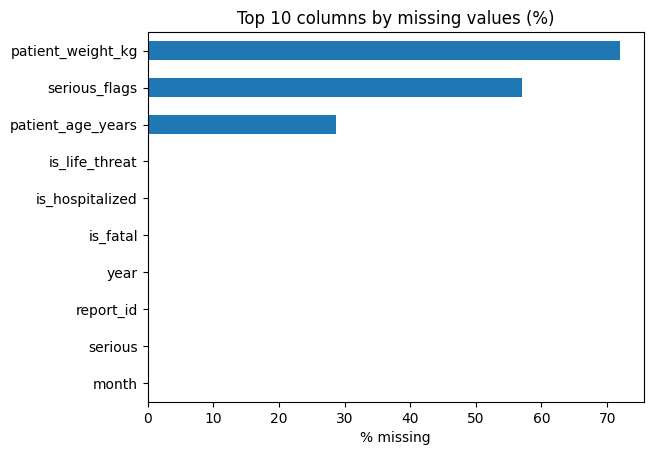

In [9]:
missing.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 columns by missing values (%)")
plt.xlabel("% missing")
plt.savefig("images/missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** `patient_weight_kg` is the most incomplete column (about 72% missing), followed by `serious_flags` (about 57%, an outcome column that will be dropped anyway) and `patient_age_years` (about 29%). Every other column is complete. Some columns hide missing values as the text "Unknown", which `isna()` cannot detect.

In [10]:
df["report_id"].duplicated().sum()

np.int64(0)

**Interpretation:** There are 0 duplicate report IDs, so no de-duplication is needed.

In [11]:
df.nunique()

,0
report_id,528000
receive_date,3974
year,11
month,12
quarter,44
serious,2
serious_flags,31
is_fatal,2
is_hospitalized,2
is_life_threat,2


**Interpretation:** `reactions` (371,324 values), `primary_reaction` (10,446), `suspect_drug` (9,828) and `drug_indication` (5,385) have far too many categories for direct one-hot encoding, so only the most frequent categories will be kept later. `receive_date` and `report_age_days` both have 3,974 values, so they carry the same information.

## 4. Target variable: serious vs non-serious

In [12]:
df["serious"].value_counts()

,count
serious,
Yes,395000
No,133000


In [13]:
df["serious"].value_counts(normalize=True) * 100

,proportion
serious,
Yes,74.810606
No,25.189394


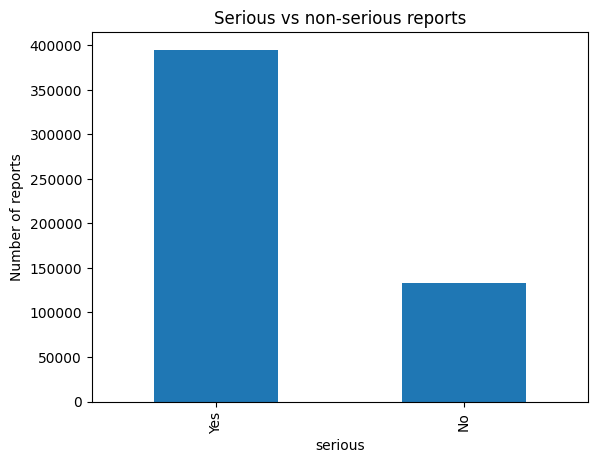

In [14]:
df["serious"].value_counts().plot(kind="bar")
plt.title("Serious vs non-serious reports")
plt.ylabel("Number of reports")
plt.savefig("images/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** 395,000 reports (74.81%) are serious and 133,000 (25.19%) are not. The classes are imbalanced at roughly 3:1, so accuracy alone can be misleading, because a model that always predicts "serious" would already be 74.8% accurate. Precision, recall, F1 and AUC-ROC will also be used.

In [15]:
df["target"] = (df["serious"] == "Yes").astype(int)

**Interpretation:** A 0/1 column `target` is created (1 = serious) so that the mean of `target` directly gives the serious rate in the following steps.

## 5. Outcome columns (leakage check)

In [16]:
df["serious_flags"].value_counts().head(10)

,count
serious_flags,
Hospitalization,142536
Death,24407
Death; Hospitalization,22828
Hospitalization; Life-Threatening,11163
Disability,5763
Hospitalization; Disability,4544
Life-Threatening,4309
Death; Hospitalization; Life-Threatening,3795
Congenital Anomaly,2051


**Interpretation:** `serious_flags` lists the type of seriousness. Hospitalization is the most common (142,536 reports), followed by Death (24,407) and Death with Hospitalization (22,828). The column is filled in only 226,894 rows, so at least 168,106 serious reports carry no flag. It is therefore not a complete copy of the target, but it is still an outcome column recorded after the event, so it cannot be used as a feature.

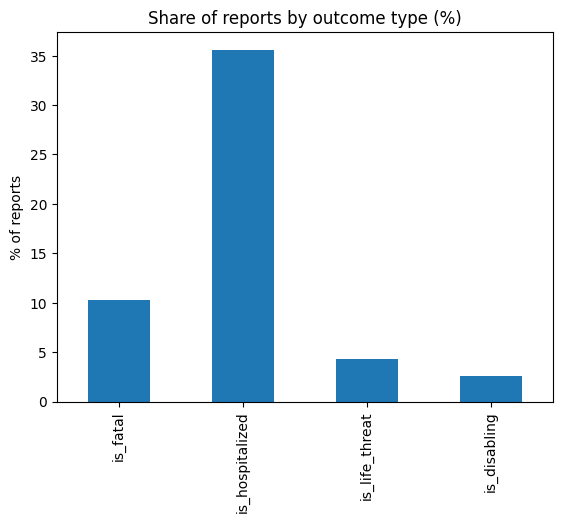

In [17]:
outcome_cols = ["is_fatal", "is_hospitalized", "is_life_threat", "is_disabling"]
(df[outcome_cols].mean() * 100).plot(kind="bar")
plt.title("Share of reports by outcome type (%)")
plt.ylabel("% of reports")
plt.savefig("images/outcome_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** About 10% of reports are fatal, 35.5% involve hospitalization, 4% are life-threatening and 2.5% involve disability. Hospitalization is by far the most common outcome. These four flags together cover at most about 52% of reports, while 74.8% are serious, so at least a fifth of all reports are serious for other reasons (for example congenital anomaly or other important medical events). All four flags are known only after the event, so they are excluded from the features to avoid leakage. The same applies to `serious_flags`, `reaction_outcomes` and `patient_recovered`.

## 6. Patient demographics
### 6.1 Age group

In [18]:
df["age_group"].value_counts()

,count
age_group,
Middle-Aged(41-65),166278
Unknown,152337
Senior(66-80),108781
Adult(19-40),53277
Elderly(81+),25842
Child(3-12),9767
Teen(13-18),8617
Infant(0-2),3101


In [19]:
(df.groupby("age_group")["target"].mean() * 100).round(1)

,target
age_group,
Adult(19-40),79.5
Child(3-12),67.8
Elderly(81+),81.1
Infant(0-2),90.3
Middle-Aged(41-65),78.3
Senior(66-80),79.1
Teen(13-18),72.6
Unknown,65.5


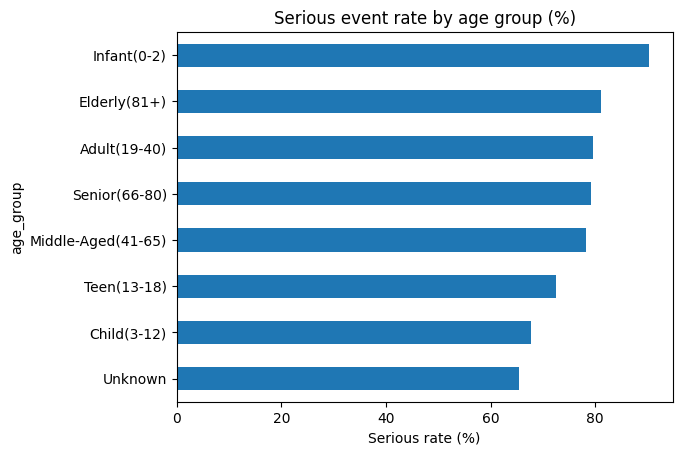

In [20]:
(df.groupby("age_group")["target"].mean() * 100).sort_values().plot(kind="barh")
plt.title("Serious event rate by age group (%)")
plt.xlabel("Serious rate (%)")
plt.savefig("images/age_group.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Infants (0-2) have the highest serious rate at 90.3%, followed by Elderly (81+) at 81.1%. Children (3-12) are at 67.8% and teens at 72.6%. The "Unknown" group is large (152,337 reports, about 29%) and has the lowest rate (65.5%). Infants have only 3,101 reports, so their percentage rests on a small sample.

### 6.2 Sex

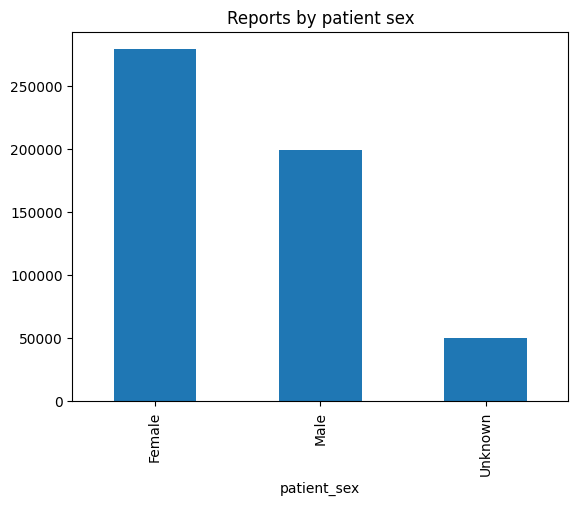

In [21]:
df["patient_sex"].value_counts().plot(kind="bar")
plt.title("Reports by patient sex")
plt.savefig("images/sex_count.png", dpi=150, bbox_inches="tight")
plt.show()

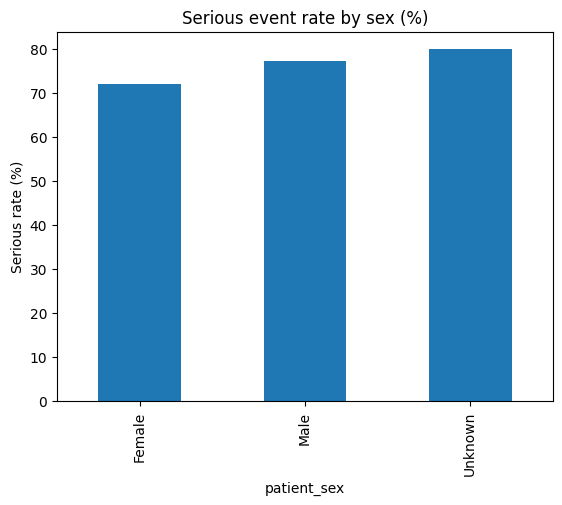

In [22]:
(df.groupby("patient_sex")["target"].mean() * 100).plot(kind="bar")
plt.title("Serious event rate by sex (%)")
plt.ylabel("Serious rate (%)")
plt.savefig("images/sex_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** There are about 280k female, 200k male and 50k unknown-sex reports. The serious rate is about 72% for females, 77% for males and 80% for unknown. The differences are small, so sex is a weak predictor.

### 6.3 Age and weight distributions

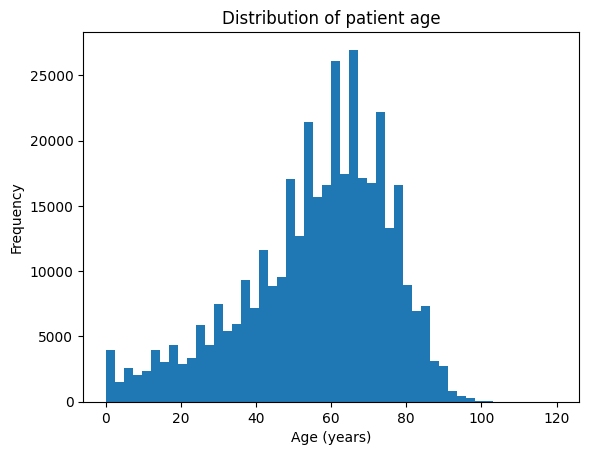

In [23]:
df["patient_age_years"].plot(kind="hist", bins=50)
plt.title("Distribution of patient age")
plt.xlabel("Age (years)")
plt.savefig("images/age_hist.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Most reports are for patients aged 50-75 (mean 55.9, median 59). There is a small spike near age 0 (infants) and very few patients above 90. The distribution is left-skewed.

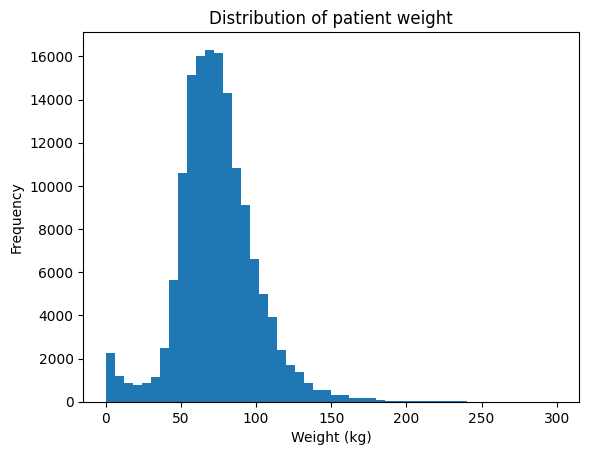

In [24]:
df["patient_weight_kg"].plot(kind="hist", bins=50)
plt.title("Distribution of patient weight")
plt.xlabel("Weight (kg)")
plt.savefig("images/weight_hist.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Weight peaks around 70 kg (mean 74.3, median 72.6). A small cluster near 0-5 kg most likely belongs to infants. The right tail is long, reaching 300 kg.

In [25]:
df[["patient_age_years", "patient_weight_kg"]].describe()

,patient_age_years,patient_weight_kg
count,376491.000000,148077.000000
mean,55.942629,74.343911
std,19.567057,26.273915
min,0.000000,0.050000
25%,45.000000,59.000000
50%,59.000000,72.560000
75%,70.000000,88.435000
max,120.000000,300.000000


**Interpretation:** Age ranges from 0 to 120 and weight from 0.05 kg to 300 kg. These are extreme but not impossible values, so they are kept.

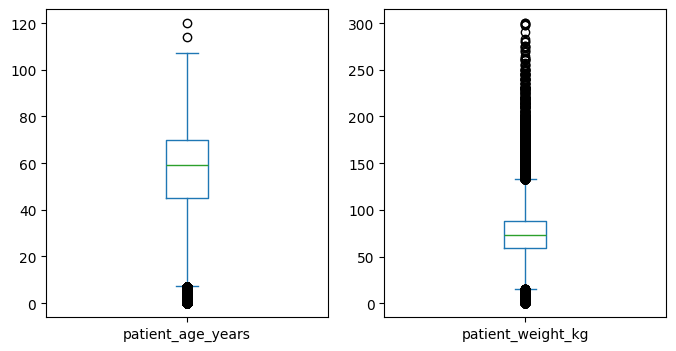

In [26]:
df[["patient_age_years", "patient_weight_kg"]].plot(kind="box", subplots=True, figsize=(8, 4))
plt.savefig("images/age_weight_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Both variables show outliers (very old and very heavy patients). Tree-based models are not sensitive to outliers, and the median is used to fill missing values for the same reason.

In [27]:
(df["patient_age_years"] > 100).sum()

np.int64(28)

**Interpretation:** Only 28 reports have an age above 100, which is negligible and needs no special handling.

### 6.4 Is missingness itself informative?

In [28]:
df.groupby(df["patient_age_years"].isna())["target"].mean() * 100

,target
patient_age_years,
False,78.614894
True,65.357174


**Interpretation:** Reports with missing age are serious 65.4% of the time, against 78.6% when age is present. Missing age is itself informative, so a missing-age flag will be created in preprocessing.

In [29]:
df.groupby(df["patient_weight_kg"].isna())["target"].mean() * 100

,target
patient_weight_kg,
False,82.709671
True,71.731904


**Interpretation:** Reports with weight recorded are serious 82.7% of the time, against 71.7% when weight is missing. Weight missingness is also a useful flag.

### 6.5 Country

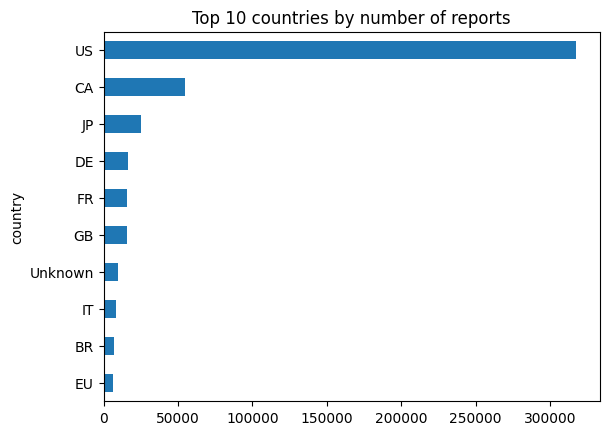

In [30]:
df["country"].value_counts().head(10).sort_values().plot(kind="barh")
plt.title("Top 10 countries by number of reports")
plt.savefig("images/top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The US dominates with about 318k reports (around 60%), followed by Canada, Japan, Germany, France and the UK. Conclusions will be most reliable for US reports.

In [31]:
(df.groupby(df["country"] == "US")["target"].agg(["mean", "count"]))

,mean,count
country,,
False,0.973089,210544
True,0.598892,317456


**Interpretation:** US reports (317,456 reports, about 60% of the data) have a serious rate of 59.9%, while all non-US reports together (210,544 reports, about 40%) have a serious rate of 97.3%. This gap of about 37 percentage points is larger than the gap seen for age group, number of drugs or number of reactions, so whether a report comes from the US is likely to be a very strong predictor. This probably reflects reporting rules and not medical risk, so model results will be reported with and without `country`.

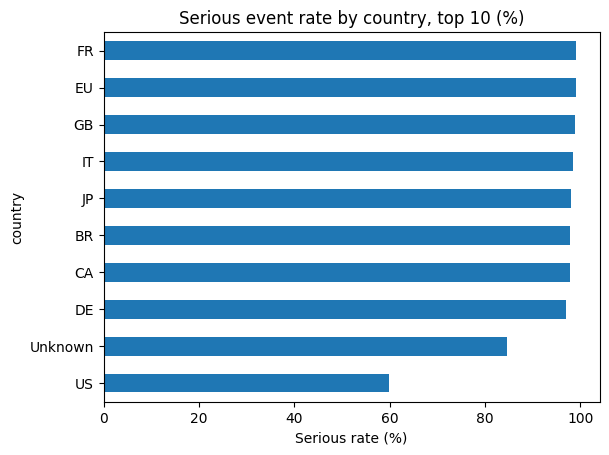

In [32]:
top_countries = df["country"].value_counts().head(10).index
(df[df["country"].isin(top_countries)].groupby("country")["target"].mean() * 100).sort_values().plot(kind="barh")
plt.title("Serious event rate by country, top 10 (%)")
plt.xlabel("Serious rate (%)")
plt.savefig("images/country_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The serious rate in the US is only about 60%, while almost every other country in the top 10 is at 97-99% (France, EU, UK, Italy, Japan, Brazil, Canada, Germany). Reports with an unknown country are at about 85%. So nearly all non-US reports are serious. A likely reason is that foreign cases reach the FDA mainly when they are serious, which is a reporting rule and not a medical difference. This is a possibility and cannot be confirmed from this data. `country` is therefore a very strong predictor, and the model may partly learn "non-US means serious".

## 7. Drug-related variables
### 7.1 Number of drugs (polypharmacy)

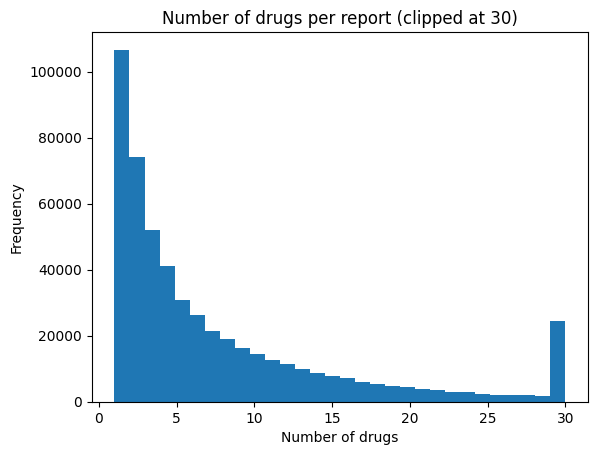

In [33]:
df["num_drugs"].clip(upper=30).plot(kind="hist", bins=30)
plt.title("Number of drugs per report (clipped at 30)")
plt.xlabel("Number of drugs")
plt.savefig("images/num_drugs_hist.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Most reports list 1-5 drugs. The tall bar at 30 is created by clipping: about 24,000 reports have 30 or more drugs.

In [34]:
df["drug_count_category"].value_counts()

,count
drug_count_category,
Polypharmacy(6+),221528
2-3 Drugs,126066
Single,106633
4-5 Drugs,71972
Unknown,1801


In [35]:
(df.groupby("drug_count_category")["target"].mean() * 100).round(1)

,target
drug_count_category,
2-3 Drugs,67.3
4-5 Drugs,77.6
Polypharmacy(6+),85.7
Single,58.8
Unknown,99.8


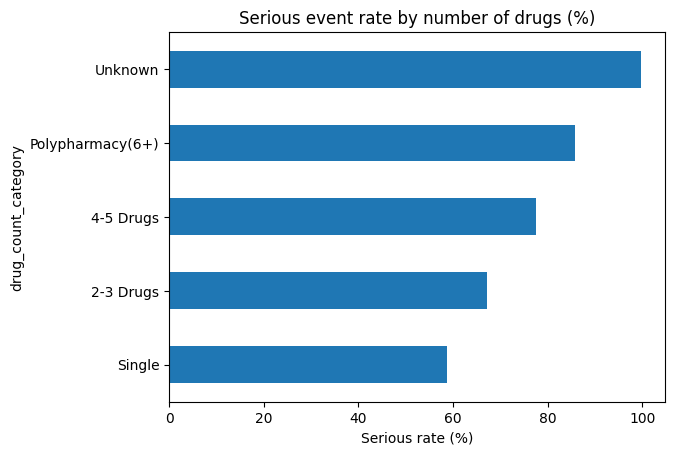

In [36]:
(df.groupby("drug_count_category")["target"].mean() * 100).sort_values().plot(kind="barh")
plt.title("Serious event rate by number of drugs (%)")
plt.xlabel("Serious rate (%)")
plt.savefig("images/polypharmacy.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The serious rate rises with the number of drugs: Single 58.8%, 2-3 drugs 67.3%, 4-5 drugs 77.6% and 6+ drugs 85.7%, a gap of about 27 points. The "Unknown" category (1,801 reports, 99.8%) is too small and unusual to draw conclusions from.

### 7.2 Suspect drugs

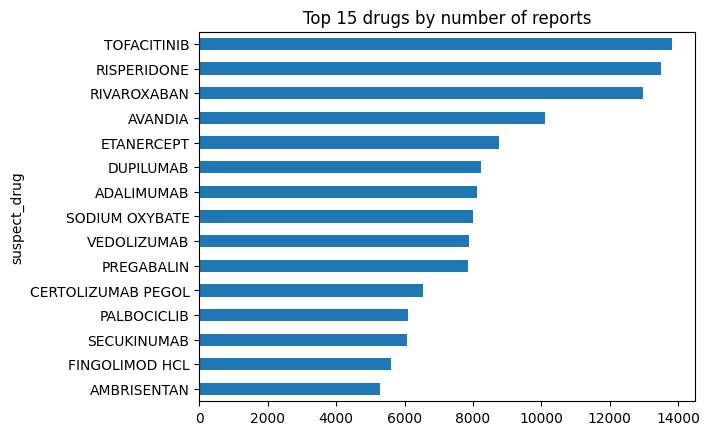

In [37]:
df["suspect_drug"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 drugs by number of reports")
plt.savefig("images/top_drugs.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Tofacitinib, Risperidone and Rivaroxaban have the most reports (about 13,000-14,000 each), followed by Avandia, Etanercept and Dupilumab. Most are used for long-term conditions.

In [38]:
g = df.groupby("suspect_drug")["target"].agg(["mean", "count"])
g[g["count"] >= 500].sort_values("mean", ascending=False).head(10)

,mean,count
suspect_drug,,
"CYCLOPHOSPHAMIDE FOR INJECTION; CYCLOPHOSPHAMIDE; CYCLOPHOSPHAMIDE INJECTION, SOLUTION",0.996485,569
PREDNISOLONE; PREDNISOLONE ORAL; PREDNISOLONE ORAL SOLUTION,0.993856,651
ZANTAC,0.992765,4561
LANSOPRAZOLE,0.991837,1960
JAKAVI,0.991686,842
ATEZOLIZUMAB,0.991435,1401
OXALIPLATIN,0.991087,561
RIVAROXABAN,0.990901,12968
CARBOPLATIN,0.990323,930


**Interpretation:** Among drugs with at least 500 reports, the highest serious rates are all near 99%: Cyclophosphamide, Prednisolone, Zantac, Lansoprazole, Jakavi, Atezolizumab and others. They are not all chemotherapy drugs. The next cell checks whether the country mix explains these rates.

In [39]:
top10 = g[g["count"] >= 500].sort_values("mean", ascending=False).head(10).index
check = df[df["suspect_drug"].isin(top10)].groupby("suspect_drug")
pd.DataFrame({"share_of_US_reports_%": check["country"].apply(lambda s: (s == "US").mean() * 100),
              "serious_rate_%": check["target"].mean() * 100}).round(1)

,share_of_US_reports_%,serious_rate_%
suspect_drug,,
ATEZOLIZUMAB,8.6,99.1
CARBOPLATIN,22.5,99.0
"CYCLOPHOSPHAMIDE FOR INJECTION; CYCLOPHOSPHAMIDE; CYCLOPHOSPHAMIDE INJECTION, SOLUTION",18.6,99.6
DABIGATRAN ETEXILATE MESYLATE; DABIGATRAN ETEXILATE,81.6,98.9
JAKAVI,0.1,99.2
LANSOPRAZOLE,88.7,99.2
OXALIPLATIN,15.5,99.1
PREDNISOLONE; PREDNISOLONE ORAL; PREDNISOLONE ORAL SOLUTION,5.1,99.4
RIVAROXABAN,95.1,99.1


**Interpretation:** Two different patterns appear. Jakavi (0.1% US reports), Prednisolone (5.1%), Atezolizumab (8.6%), Oxaliplatin (15.5%), Cyclophosphamide (18.6%) and Carboplatin (22.5%) are almost entirely non-US, and non-US reports are almost always serious (section 6.5), so their ~99% rates are largely a country effect. In contrast, Zantac (99.5% US), Rivaroxaban (95.1%), Lansoprazole (88.7%) and Dabigatran (81.6%) are mostly US reports, yet are also ~99% serious, far above the US average of about 60%. The country mix cannot explain these. A possible reason is the way these reports were collected (for example, reports linked to legal claims), but this cannot be confirmed from the data. These drugs should be treated with caution, and the high rates should not be read as these drugs being more dangerous than others.

### 7.3 Route of administration

In [40]:
df["drug_route"].value_counts().head(10)

,count
drug_route,
48.0,196194
65.0,96762
Unknown,81843
58.0,56742
42.0,50284
41.0,10937
50.0,6258
30.0,5821
64.0,4484


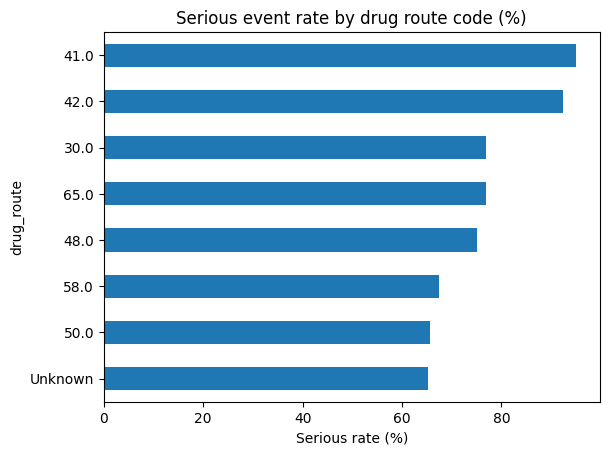

In [41]:
top_routes = df["drug_route"].value_counts().head(8).index
(df[df["drug_route"].isin(top_routes)].groupby("drug_route")["target"].mean() * 100).sort_values().plot(kind="barh")
plt.title("Serious event rate by drug route code (%)")
plt.xlabel("Serious rate (%)")
plt.savefig("images/route_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Routes are stored as numeric codes, not names, so they will be treated as categories. Code 48 is the most common (196,194 reports), followed by code 65 and Unknown. Codes 41 and 42 have the highest serious rates (about 95% and 92%), while the others lie between 65% and 77%.


### 7.4 Pharmacologic class, manufacturer and indication

In [42]:
df["pharm_class"].value_counts().head(10)

,count
pharm_class,
Unknown,235513
Tumor Necrosis Factor Blocker [EPC],27036
Atypical Antipsychotic [EPC],19268
Factor Xa Inhibitor [EPC],13839
Kinase Inhibitor [EPC],12482
Integrin Receptor Antagonist [EPC],11087
CD20-directed Cytolytic Antibody [EPC],9955
Interleukin-4 Receptor alpha Antagonist [EPC],8246
Programmed Death Receptor-1 Blocking Antibody [EPC],7895


**Interpretation:** 235,513 reports (about 45%) have an "Unknown" pharmacologic class. Among known classes, TNF blockers, atypical antipsychotics and Factor Xa inhibitors are the most common.

In [43]:
df.groupby(df["pharm_class"] == "Unknown")["target"].mean() * 100

,target
pharm_class,
False,72.661349
True,77.479799


**Interpretation:** The serious rate is 77.5% when the class is Unknown and 72.7% when it is known. The difference is small.

In [44]:
df["manufacturer"].value_counts().head(10)

,count
manufacturer,
Unknown,76027
"Janssen Pharmaceuticals, Inc.",27054
Novartis Pharmaceuticals Corporation,25985
Pfizer Laboratories Div Pfizer Inc; U.S. Pharmaceuticals,20863
"Genentech, Inc.",19543
"Takeda Pharmaceuticals America, Inc.",15336
Sanofi-Aventis U.S. Llc,12892
"E.R. Squibb & Sons, L.L.C.",10984
Parke-Davis Div Of Pfizer Inc; Viatris Specialty Llc,9643


**Interpretation:** 76,027 reports have an Unknown manufacturer. Among the named ones, Janssen, Novartis and Pfizer are the largest.

In [45]:
df["drug_indication"].value_counts().head(10)

,count
drug_indication,
Unknown,70172
Product Used For Unknown Indication,63460
Rheumatoid Arthritis,29064
Multiple Sclerosis,16878
Diabetes Mellitus,12636
Crohn^S Disease,11994
Hiv Infection,9885
Psoriasis,7788
Plasma Cell Myeloma,7366


**Interpretation:** "Unknown" and "Product Used For Unknown Indication" together cover about 133,000 reports (25%) and mean the same thing. The most common named indications are Rheumatoid Arthritis, Multiple Sclerosis and Diabetes Mellitus.

## 8. Reactions

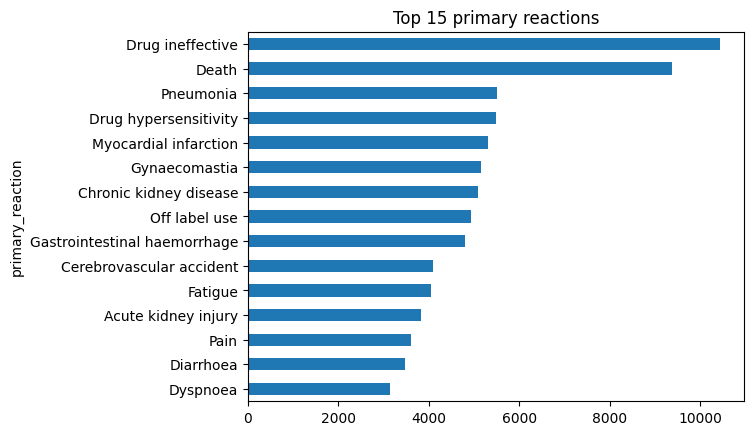

In [46]:
df["primary_reaction"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 primary reactions")
plt.savefig("images/top_reactions.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** "Drug ineffective" is the most common reaction (about 10,400), followed by "Death" (about 9,400), Pneumonia and Drug hypersensitivity.

In [47]:
df.groupby(df["primary_reaction"] == "Death")["target"].mean() * 100

,target
primary_reaction,
False,74.355464
True,100.000000


**Interpretation:** Every report whose primary reaction is "Death" is serious (100%), against 74.4% for the rest. This is target leakage, because the reaction itself is the outcome.

In [48]:
df["reactions"].str.contains("Death", case=False).mean() * 100

np.float64(2.7181818181818183)

**Interpretation:** About 2.72% of reports (around 14,000) mention "Death" somewhere in the reaction list, so the `reactions` column is also a leakage risk. Both reaction text columns are dropped before modelling.

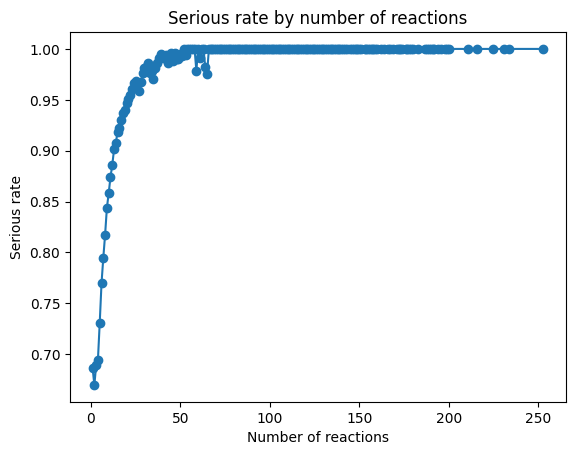

In [49]:
df.groupby("num_reactions")["target"].mean().plot(marker="o")
plt.title("Serious rate by number of reactions")
plt.xlabel("Number of reactions")
plt.ylabel("Serious rate")
plt.savefig("images/num_reactions_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The serious rate climbs steeply with the number of reactions, from about 67% at one reaction to nearly 100% beyond 30. This is a strong, non-linear relationship. Reports with many reactions may simply be filled in more thoroughly for serious cases.

In [50]:
bins = pd.cut(df["num_reactions"], [0, 1, 3, 5, 10, 30, 300])
(df.groupby(bins, observed=True)["target"].mean() * 100).round(1)

,target
num_reactions,
"(0, 1]",68.6
"(1, 3]",67.8
"(3, 5]",71.0
"(5, 10]",80.7
"(10, 30]",92.0
"(30, 300]",98.8


**Interpretation:** Grouping the reaction counts into ranges confirms the pattern in a simple table: the more reactions listed, the higher the serious rate.

## 9. Trend over time

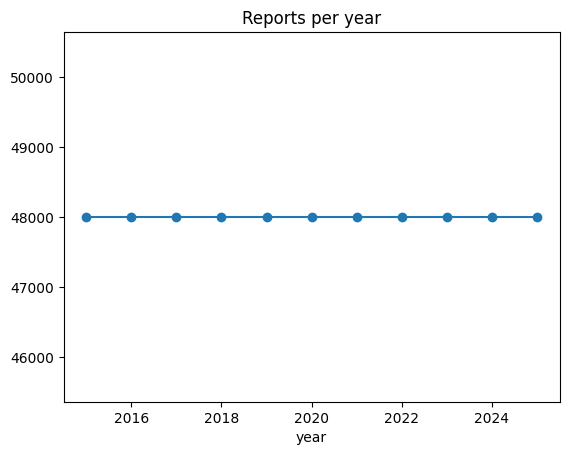

In [51]:
df.groupby("year").size().plot(marker="o")
plt.title("Reports per year")
plt.savefig("images/reports_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Every year from 2015 to 2025 has exactly 48,000 reports, so the dataset was sampled evenly by year. Report volume therefore says nothing about real-world trends and should not be interpreted.

In [52]:
df["receive_date"].min(), df["receive_date"].max()

('2015-01-01', '2025-12-31')

**Interpretation:** The data runs from 2015-01-01 to 2025-12-31. There are no 2026 reports.

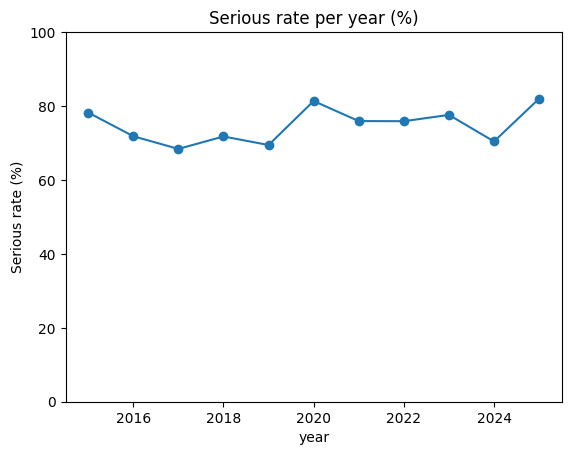

In [53]:
(df.groupby("year")["target"].mean() * 100).plot(marker="o", ylim=(0, 100))
plt.title("Serious rate per year (%)")
plt.ylabel("Serious rate (%)")
plt.savefig("images/serious_rate_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The yearly serious rate moves between about 68% (2017) and 82% (2025) with no steady upward or downward trend. On a 0-100 axis the variation is moderate, about 14 points at most.

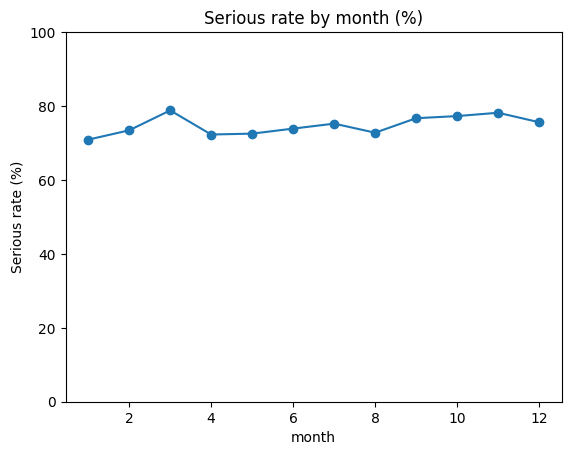

In [54]:
(df.groupby("month")["target"].mean() * 100).plot(marker="o", ylim=(0, 100))
plt.title("Serious rate by month (%)")
plt.ylabel("Serious rate (%)")
plt.savefig("images/month_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The monthly serious rate stays between about 71% and 79% with no clear seasonal pattern, so month is a weak feature.

## 10. Correlation with the target

In [55]:
num_cols = ["num_drugs", "num_reactions", "patient_age_years", "patient_weight_kg", "target"]
df[num_cols].corr()["target"]

,target
num_drugs,0.126050
num_reactions,0.177519
patient_age_years,0.019228
patient_weight_kg,-0.029215
target,1.000000


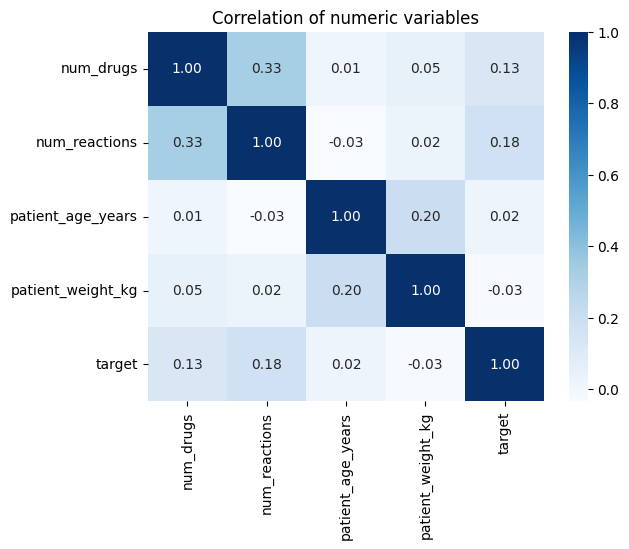

In [56]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation of numeric variables")
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** `num_reactions` (0.178) and `num_drugs` (0.126) have the strongest linear correlation with the target. Age (0.019) and weight (-0.029) are weak. Among the predictors themselves, the strongest correlation is between `num_drugs` and `num_reactions` (0.33), followed by age and weight (0.20); all other pairs are close to 0, so there is no strong multicollinearity among the numeric variables. Because the reactions relationship is curved, tree-based models such as Random Forest should capture it better than Logistic Regression.

## 11. Summary of EDA findings

1. The dataset has 528,000 reports and 74.8% are serious (imbalanced, about 3:1).
2. Infants (90.3%) and the elderly (81.1%) have the highest serious rates.
3. The serious rate rises with the number of drugs (58.8% for one drug to 85.7% for 6+).
4. The serious rate rises sharply with the number of reactions listed.
5. Missing age and missing weight are themselves informative.
6. The dataset has exactly 48,000 reports per year (2015-2025), so report volume trends are not meaningful.
7. The data is US-heavy (about 60% of reports).
8. Large shares of "Unknown" values exist in pharm class (45%), manufacturer (14%) and indication (25%).

**Decisions for preprocessing:**
- Drop leakage columns: `serious`, `serious_flags`, `is_fatal`, `is_hospitalized`, `is_life_threat`, `is_disabling`, `reaction_outcomes`, `patient_recovered`, `reactions`, `primary_reaction`.
- Drop redundant columns: `report_id`, `receive_date`, `report_age_days`, `quarter`, `year`, `month`, `brand_name`.
- Create `age_missing` and `weight_missing` flags, then fill missing values with the median.
- Keep the top categories of high-cardinality columns and group the rest as "Other".
- Treat `drug_route` codes as categories.

# Part 2 - Data Preprocessing

**Objective:** Prepare the data for modelling using the decisions made in the EDA.

**Steps:**
1. Create missing-value flags and clean two columns
2. Drop leakage and redundant columns
3. Log-transform skewed counts
4. Split into train and test sets (80/20, stratified)
5. Fill missing values, group rare categories, encode and scale, learning all statistics from the **train set only**
6. Save the processed data

The split is made before any statistic is learned, so no information from the test set reaches the model.

## 12. Imports and target check

In [57]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [58]:
df["target"] = (df["serious"] == "Yes").astype(int)
os.makedirs("data", exist_ok=True)

**Interpretation:** The extra libraries for preprocessing are imported, and the 0/1 `target` column (1 = serious) is made sure to exist. A `data/` folder is created for the processed files.

## 13. Missing-value flags and column clean-up

In [59]:
df["age_missing"] = df["patient_age_years"].isna().astype(int)
df["weight_missing"] = df["patient_weight_kg"].isna().astype(int)

**Interpretation:** In the EDA, reports with missing age (65.4% serious) and missing weight (71.7%) differed from reports where these values were present (78.6% and 82.7%). Two flag columns keep this information. They must be created before the missing values are filled. This step works row by row, so it uses no information from other rows.

In [60]:
df["drug_indication"] = df["drug_indication"].replace("Product Used For Unknown Indication", "Unknown")
df["drug_route"] = df["drug_route"].astype(str)

**Interpretation:** "Unknown" and "Product Used For Unknown Indication" mean the same thing, so they are merged into one category. The route codes (such as 48.0 and 65.0) are labels and not quantities, so they are converted to text and will be treated as categories.

## 14. Dropping columns

In [61]:
drop_cols = ["serious", "serious_flags", "is_fatal", "is_hospitalized", "is_life_threat", "is_disabling",
             "reaction_outcomes", "patient_recovered", "reactions", "primary_reaction",
             "report_id", "receive_date", "report_age_days", "quarter", "year", "month", "brand_name"]
df2 = df.drop(columns=drop_cols)
df2.shape

(528000, 16)

**Interpretation:** 17 columns were dropped. The cleaned data has 528,000 rows and 16 columns (15 features and the target).

- **Outcome (leakage):** `serious`, `serious_flags`, `is_fatal`, `is_hospitalized`, `is_life_threat`, `is_disabling`, `reaction_outcomes`, `patient_recovered`. These are known only after the event.
- **Reaction text (leakage):** `reactions` and `primary_reaction` contain outcomes such as "Death" (100% serious in the EDA).
- **Redundant or uninformative:** `report_id` (identifier), `receive_date`, `report_age_days` and `quarter` (same information as the date), `year` and `month` (no useful pattern, and year is fixed at 48,000 reports), and `brand_name` (overlaps with `suspect_drug`).

## 15. Transformation of skewed counts

In [62]:
df2["num_drugs"] = np.log1p(df2["num_drugs"])
df2["num_reactions"] = np.log1p(df2["num_reactions"])

**Interpretation:** `num_drugs` (maximum 2,108) and `num_reactions` (maximum 253) are strongly right-skewed. A log transformation, log(1 + x), reduces the effect of the extreme values. It helps mainly Logistic Regression and does not change the results of tree-based models. It works row by row, so it does not leak information.

## 16. Train/test split

In [63]:
X = df2.drop(columns="target")
y = df2["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(422400, 15) (105600, 15)
0.7481060606060606 0.7481060606060606


**Interpretation:** The data is split 80/20 into 422,400 training and 105,600 test reports. Stratification keeps the share of serious reports (about 74.8%) the same in both sets, and `random_state=42` makes the split reproducible. From here on, every statistic is learned from the training set only.

## 17. Filling missing values

In [64]:
X_train = X_train.copy()
X_test = X_test.copy()
age_median = X_train["patient_age_years"].median()
weight_median = X_train["patient_weight_kg"].median()
X_train["patient_age_years"] = X_train["patient_age_years"].fillna(age_median)
X_test["patient_age_years"] = X_test["patient_age_years"].fillna(age_median)
X_train["patient_weight_kg"] = X_train["patient_weight_kg"].fillna(weight_median)
X_test["patient_weight_kg"] = X_test["patient_weight_kg"].fillna(weight_median)

In [65]:
X_train.isna().sum().sum(), X_test.isna().sum().sum()

(np.int64(0), np.int64(0))

**Interpretation:** Missing age and weight are filled with the median of the training set, which is not distorted by extreme values such as 300 kg. The same training medians are used for the test set. Both sets now have 0 missing values, and the flag columns still record which values were originally missing.

## 18. Grouping rare categories

In [66]:
cat_cols = ["suspect_drug", "manufacturer", "pharm_class", "drug_indication", "country", "drug_route"]
for c in cat_cols:
    top20 = X_train[c].value_counts().head(20).index
    X_train[c] = X_train[c].where(X_train[c].isin(top20), "Other")
    X_test[c] = X_test[c].where(X_test[c].isin(top20), "Other")

In [67]:
X_train["suspect_drug"].value_counts().head(8)

,count
suspect_drug,
Other,300613
TOFACITINIB,11088
RISPERIDONE,10734
RIVAROXABAN,10414
AVANDIA,8148
ETANERCEPT,6989
DUPILUMAB,6674
ADALIMUMAB,6469


**Interpretation:** `suspect_drug` (9,828 values), `manufacturer` (1,570), `pharm_class` (448), `drug_indication` (5,385), `country` (162) and `drug_route` (62) have too many categories for one-hot encoding. For each column, the 20 most frequent categories are chosen from the training set and all others become "Other". Test categories that are not in this list also become "Other". The model therefore has less detail about rare drugs and countries.

## 19. Encoding categorical variables

In [68]:
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [69]:
print(X_train.shape, X_test.shape)
print((X_train.columns == X_test.columns).all())

(422400, 139) (105600, 139)
True


**Interpretation:** Every text column is turned into 0/1 columns (one-hot encoding). One category per column is dropped (`drop_first=True`) to avoid perfectly overlapping columns. The test set is reordered to match the training columns exactly, so both sets have the same number of columns and the check returns `True`. All features are now numeric.

## 20. Scaling numeric features

In [70]:
num_cols = ["num_reactions", "num_drugs", "patient_age_years", "patient_weight_kg"]
sc = StandardScaler()
X_train[num_cols] = sc.fit_transform(X_train[num_cols])
X_test[num_cols] = sc.transform(X_test[num_cols])

In [71]:
X_train[num_cols].describe().round(2)

,num_reactions,num_drugs,patient_age_years,patient_weight_kg
count,422400.00,422400.00,422400.00,422400.00
mean,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.22,-1.22,-3.43,-5.24
25%,-0.69,-0.77,-0.29,-0.04
50%,-0.03,-0.19,0.13,-0.04
75%,0.58,0.69,0.55,-0.04
max,5.07,6.30,3.81,16.27


**Interpretation:** The four numeric columns are standardised to mean 0 and standard deviation 1. The mean and standard deviation come from the training set only and are applied to the test set. In the output, the training columns have a mean of about 0 and a standard deviation of about 1. Scaling is needed for Logistic Regression and does not affect Random Forest. The 0/1 columns are not scaled.

## 21. Saving the processed data

In [72]:
X_train.to_parquet("data/X_train.parquet")
X_test.to_parquet("data/X_test.parquet")
y_train.to_frame().to_parquet("data/y_train.parquet")
y_test.to_frame().to_parquet("data/y_test.parquet")

**Interpretation:** The four processed files are saved in the `data/` folder. The modelling part can load them directly, so preprocessing does not need to be repeated.

## 22. Summary of preprocessing

- Target `serious` converted to 1/0.
- 17 leakage and redundant columns dropped.
- `age_missing` and `weight_missing` flags added.
- `num_drugs` and `num_reactions` log-transformed.
- 80/20 stratified split (`random_state=42`).
- Missing age and weight filled with the training median.
- Top 20 categories kept for six high-cardinality columns, the rest grouped as "Other".
- One-hot encoding and standard scaling, both learned from the training set only.

**Limitations to mention in the README:**
- `country` is a very strong predictor (US 59.9% vs non-US 97.3% serious), likely because of reporting rules, so results will be shown with and without it.
- `drug_count_category = Unknown` (1,801 reports, 99.8% serious) is an unusual group that the model may learn as a shortcut.
- Reports were sampled at exactly 48,000 per year, so time-trend conclusions are not possible.

# Part 3 - Model Training and Evaluation

**Objective:** Predict whether a report is serious, using only information available when the report is submitted.

**Models:** Logistic Regression (baseline) and Random Forest.

**Three feature sets are compared**, because two variables may give the model a shortcut:
- **Version A:** all features
- **Version B:** without `country` (non-US reports are almost always serious)
- **Version C:** without `country` and `suspect_drug` (some drugs have a serious rate of about 99%)

**Metrics:** Accuracy, Precision, Recall, F1 and AUC-ROC. Because 74.8% of reports are serious, accuracy alone is not enough.

In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
print("Accuracy if we always predict 'serious':", round(y_test.mean(), 4))

Accuracy if we always predict 'serious': 0.7481


**Interpretation:** A model that always predicts "serious" would be 74.81% accurate without learning anything. Any real model must beat this baseline, which is why Precision, Recall, F1 and AUC-ROC are also reported.

In [74]:
def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    row = {"Model": name,
           "Accuracy": accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred),
           "Recall": recall_score(y_test, pred),
           "F1": f1_score(y_test, pred),
           "AUC": roc_auc_score(y_test, p)}
    return row, p

**Interpretation:** The function `evaluate` trains a model on a given feature set, predicts the probability of a serious report for the test set, converts it to a class using a 0.5 threshold, and returns Accuracy, Precision, Recall, F1 and AUC. Using one function for every model makes sure all models are evaluated in exactly the same way.

In [75]:
country_cols = [c for c in X_train.columns if c.startswith("country_")]
drug_cols = [c for c in X_train.columns if c.startswith("suspect_drug_")]

XA_train, XA_test = X_train, X_test
XB_train, XB_test = X_train.drop(columns=country_cols), X_test.drop(columns=country_cols)
XC_train, XC_test = XB_train.drop(columns=drug_cols), XB_test.drop(columns=drug_cols)

print(len(country_cols), len(drug_cols))
print(XA_train.shape[1], XB_train.shape[1], XC_train.shape[1])

20 20
139 119 99


**Interpretation:** Three feature sets are created. Version A keeps all 139 columns. Version B removes the 20 `country` columns (119 columns left). Version C also removes the 20 `suspect_drug` columns (99 columns left). The test set is reduced in exactly the same way as the training set, so the comparison between versions is fair. The columns are fewer than 21 per variable because one category of each was dropped during one-hot encoding (`drop_first=True`).

## Version A: all features

In [76]:
results, probs = [], {}
r, p = evaluate("A - Logistic Regression", LogisticRegression(max_iter=1000), XA_train, XA_test)
results.append(r)
probs[r["Model"]] = p
r

{'Model': 'A - Logistic Regression',
 'Accuracy': 0.8373200757575757,
 'Precision': 0.8772471533007067,
 'Recall': 0.9098607594936708,
 'F1': 0.893256367398423,
 'AUC': np.float64(0.8969934560293138)}

**Interpretation:** Logistic Regression with all features reaches an accuracy of 83.73%, about 9 percentage points above the 74.81% baseline of always predicting "serious". Precision is 87.72%, so about 88 of every 100 reports flagged as serious are truly serious. Recall is 91.0%, so the model finds about 91 of every 100 truly serious reports. The F1 score is 89.33% and the AUC-ROC is 0.897, which shows a strong ability to separate serious from non-serious reports. These results include the `country` variable, which is a very strong predictor in this data, so they will be compared with the versions without `country` and `suspect_drug` (Versions B and C).

### Version A: Random Forest

In [78]:
r, p = evaluate("A - Random Forest", RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42), XA_train, XA_test)
results.append(r)
probs[r["Model"]] = p
r

{'Model': 'A - Random Forest',
 'Accuracy': 0.845814393939394,
 'Precision': 0.8694858139315675,
 'Recall': 0.9341139240506329,
 'F1': 0.9006419644600664,
 'AUC': np.float64(0.9109851970115161)}

**Interpretation:** Random Forest with all features reaches an accuracy of 84.58%, an F1 score of 90.06% and an AUC-ROC of 0.911. Compared with Logistic Regression, accuracy is about 0.9 percentage points higher, recall is higher (93.4% against 91.0%) and AUC is 0.014 higher, while precision is slightly lower (86.95% against 87.72%). The model finds about 93 of every 100 truly serious reports, at the cost of a few more false alarms. The improvement over the linear baseline is modest, which suggests that most of the signal can already be captured by a linear model. These results still include `country`, so Versions B and C are needed to see how much of this performance depends on it.

## Version B: without country

In [ ]:
r, p = evaluate("B - Logistic Regression", LogisticRegression(max_iter=1000), XB_train, XB_test)
results.append(r)
probs[r["Model"]] = p
r

**Interpretation:** After removing the `country` columns, Logistic Regression reaches an accuracy of 81.38%, an F1 score of 88.22% and an AUC-ROC of 0.841. Compared with Version A, accuracy falls by about 2.4 percentage points, precision by about 4.0 points and AUC by 0.056, so `country` carried a substantial part of the signal. Recall rises slightly (93.2% against 91.0%), which suggests the model now flags more reports as serious, at the cost of more false alarms (lower precision). The model is still about 6.6 points above the 74.81% baseline, so it does not depend on `country` alone.

### Version B: Random Forest

In [ ]:
r, p = evaluate("B - Random Forest", RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42), XB_train, XB_test)
results.append(r)
probs[r["Model"]] = p
r

**Interpretation:** After removing the `country` columns, Random Forest reaches an accuracy of 82.40%, an F1 score of 89.04% and an AUC-ROC of 0.867. Compared with Version A, accuracy falls by about 2.2 percentage points, precision by 3.6 points and AUC by 0.044, while recall rises to 95.6%. A high recall with lower precision means the model flags a large share of reports as serious and catches almost all truly serious ones, at the cost of more false alarms. Without `country`, Random Forest is still ahead of Logistic Regression (AUC 0.867 against 0.841), so non-linear patterns in the other variables add some value. Both models remain clearly above the 74.81% baseline accuracy.

## Version C: without country and suspect drug

In [ ]:
r, p = evaluate("C - Logistic Regression", LogisticRegression(max_iter=1000), XC_train, XC_test)
results.append(r)
probs[r["Model"]] = p
r

**Interpretation:** After removing both `country` and `suspect_drug`, Logistic Regression reaches an accuracy of 80.92%, an F1 score of 87.95% and an AUC-ROC of 0.834. Compared with Version B, accuracy falls by only about 0.5 percentage points and AUC by 0.007, so the top-20 `suspect_drug` columns add very little. This is expected, because 71.2% of reports were grouped as "Other" for this variable. The model is still about 6 points above the 74.81% baseline using only patient, report-count and general drug-class information (such as number of reactions, number of drugs, age, sex and route), so the prediction does not depend on country or drug name alone.

### Version C: Random Forest

In [ ]:
r, p = evaluate("C - Random Forest", RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42), XC_train, XC_test)
results.append(r)
probs[r["Model"]] = p
r

**Interpretation:** After removing both `country` and `suspect_drug`, Random Forest reaches an accuracy of 82.42%, an F1 score of 89.06% and an AUC-ROC of 0.868. These values are almost identical to Version B (accuracy 82.40%, AUC 0.867), so the top-20 `suspect_drug` columns add essentially nothing for Random Forest, which agrees with the small change seen for Logistic Regression. Most of the drug-related information is probably already present in other columns such as `pharm_class`, `drug_indication`, `num_drugs` and `drug_count_category`. Recall stays high at 95.6%, while precision stays at about 83%.

## Results: comparison of all models

In [ ]:
res = pd.DataFrame(results).set_index("Model").round(4)
res

**Interpretation:** All six models are clearly above the 74.81% baseline accuracy. Random Forest beats Logistic Regression in every version: the AUC gap is 0.014 in Version A (0.911 against 0.897), 0.026 in Version B (0.867 against 0.841) and 0.034 in Version C (0.868 against 0.834). The best model is Random Forest with all features (accuracy 84.58%, F1 90.06%, AUC 0.911). Removing `country` causes the largest drop (AUC falls by 0.044 for Random Forest and 0.056 for Logistic Regression), while additionally removing `suspect_drug` changes almost nothing. Recall stays above 91% for every model, so the models find most truly serious reports, but precision is only about 83-88%, which means a noticeable share of flagged reports are false alarms. The most realistic results, without the reporting-rule shortcut of `country`, are those of Version B and C (AUC about 0.84-0.87).

In [ ]:
res[["Accuracy", "Recall", "F1", "AUC"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model comparison")
plt.ylim(0.5, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** In every model, Recall (orange) is the highest bar and Accuracy (blue) is the lowest. Random Forest has higher AUC and Recall than Logistic Regression in all three versions. The bars drop clearly from Version A to Version B (when `country` is removed), but Versions B and C look almost the same. Note that the y-axis starts at 0.5, not at 0, which makes the differences between models look larger than they are. For example, the accuracy values only range from 0.81 to 0.85.

In [ ]:
for name in ["A - Logistic Regression", "A - Random Forest", "B - Random Forest", "C - Random Forest"]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(roc_auc_score(y_test, probs[name]), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.savefig("images/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** All curves lie far above the dashed diagonal, which represents random guessing (AUC 0.5), so every model separates serious from non-serious reports well. Random Forest with all features (AUC 0.911) is the highest curve, followed by Logistic Regression with all features (0.897). The Random Forest curves of Versions B (0.867) and C (0.868) lie almost on top of each other, so the green curve is hidden behind the red one. This confirms that removing `suspect_drug` changes nothing once `country` is gone. The gap between the upper curves (Version A) and the lower curves (Versions B and C) shows how much of the performance comes from `country`.


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
pred_A = (probs["A - Random Forest"] >= 0.5).astype(int)
cm_A = confusion_matrix(y_test, pred_A)
ConfusionMatrixDisplay(cm_A, display_labels=["Not serious", "Serious"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: A - Random Forest")
plt.savefig("images/confusion_matrix_A_RF.png", dpi=150, bbox_inches="tight")
plt.show()
cm_A

**Interpretation:** Of the 79,000 truly serious reports in the test set, the model correctly flags 73,795 (recall 93.4%) and misses 5,205 (6.6%). Of the 26,600 truly non-serious reports, it correctly identifies only 15,523 (58.4%) and wrongly flags 11,077 (41.6%) as serious. Precision is therefore 86.95%: of the 84,872 reports flagged as serious, 73,795 are truly serious. The model is much better at finding serious reports than at recognising non-serious ones. For a triage tool this is the safer direction, because a missed serious report (false negative) is more costly than an unnecessary review (false positive), but it means about 4 in 10 non-serious reports would still be sent for review. The model's weakness on the non-serious class partly reflects the class imbalance (about 3 serious reports for every non-serious one).

In [ ]:
pred_LA = (probs["A - Logistic Regression"] >= 0.5).astype(int)
cm_LA = confusion_matrix(y_test, pred_LA)
ConfusionMatrixDisplay(cm_LA, display_labels=["Not serious", "Serious"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: A - Logistic Regression")
plt.savefig("images/confusion_matrix_A_LR.png", dpi=150, bbox_inches="tight")
plt.show()
cm_LA

**Interpretation:** Of the 79,000 truly serious reports in the test set, Logistic Regression correctly flags 71,879 (recall 91.0%) and misses 7,121 (9.0%). Of the 26,600 truly non-serious reports, it correctly identifies 16,542 (62.2%) and wrongly flags 10,058 (37.8%) as serious. Precision is 87.72%: of the 81,937 reports flagged as serious, 71,879 are truly serious. Compared with the Random Forest (Version A), Logistic Regression misses more serious reports (7,121 against 5,205) but raises fewer false alarms (10,058 against 11,077), so the Random Forest is more cautious and the linear model slightly more selective. Like the Random Forest, it recognises serious reports much better than non-serious ones, which partly reflects the class imbalance (about 3 serious reports for every non-serious one).

In [ ]:
pred_B = (probs["B - Random Forest"] >= 0.5).astype(int)
cm_B = confusion_matrix(y_test, pred_B)
ConfusionMatrixDisplay(cm_B, display_labels=["Not serious", "Serious"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: B - Random Forest")
plt.savefig("images/confusion_matrix_B_RF.png", dpi=150, bbox_inches="tight")
plt.show()
cm_B

**Interpretation:** Without `country`, the Random Forest correctly flags 75,497 of the 79,000 truly serious reports (recall 95.6%) and misses only 3,503 (4.4%). However, it correctly identifies only 11,515 of the 26,600 non-serious reports (43.3%) and wrongly flags 15,085 (56.7%) as serious. Compared with Version A, the model misses fewer serious reports (3,503 against 5,205) but raises many more false alarms (15,085 against 11,077). Precision falls from 86.95% to 83.35%. Without `country`, the model becomes more cautious: it leans towards predicting "serious", which gives a very high recall but sends more than half of the non-serious reports for review. For a triage tool this trade-off could be acceptable, but it is worth noting that the model separates the two classes less sharply once the reporting-rule shortcut is removed. The decision threshold of 0.5 could be changed to balance recall and precision differently.

In [ ]:
pred_LB = (probs["B - Logistic Regression"] >= 0.5).astype(int)
cm_LB = confusion_matrix(y_test, pred_LB)
ConfusionMatrixDisplay(cm_LB, display_labels=["Not serious", "Serious"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: B - Logistic Regression")
plt.savefig("images/confusion_matrix_B_LR.png", dpi=150, bbox_inches="tight")
plt.show()
cm_LB

**Interpretation:** Without `country`, Logistic Regression correctly flags 73,610 of the 79,000 truly serious reports (recall 93.2%) and misses 5,390 (6.8%). Of the 26,600 non-serious reports, it correctly identifies only 12,329 (46.3%) and wrongly flags 14,271 (53.7%) as serious. Precision is 83.76%: of the 87,881 reports flagged as serious, 73,610 are truly serious. Compared with the same model in Version A, removing `country` lowers the misses from 7,121 to 5,390 but raises the false alarms from 10,058 to 14,271, so the model becomes more cautious and flags 83.2% of all reports as serious. Compared with the Random Forest in Version B, Logistic Regression misses more serious reports (5,390 against 3,503) but raises slightly fewer false alarms (14,271 against 15,085). The difference between the two models in this version is therefore small.

In [ ]:
rf_B = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42)
rf_B.fit(XB_train, y_train)

In [ ]:
imp = pd.Series(rf_B.feature_importances_, index=XB_train.columns).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 feature importances: B - Random Forest")
plt.xlabel("Importance")
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.head(15).round(4)

**Interpretation:** The two most important features are count variables: `num_reactions` (0.112) and `num_drugs` (0.083). This agrees with the EDA, where the serious rate rose from about 68% to 99% with the number of reactions and from 59% to 86% with the number of drugs. The drug-count category columns (`Polypharmacy(6+)` at 0.045 and `Single` at 0.028) describe the same information as `num_drugs`, so the importance of the number of drugs is shared among three columns. `patient_age_years` (0.047) and `patient_weight_kg` (0.027) are also in the list, and `age_missing` (0.022) shows that whether the age was reported is useful in itself, as seen in the EDA. Several "Unknown" categories (`manufacturer`, `drug_route`, `drug_indication`) appear, which means that incomplete reports carry information about seriousness. Two drug names (Risperidone and Dupilumab) and one drug class (PCSK9 inhibitors) also appear. These importances show which variables the model uses, not whether they raise or lower the risk, and they do not prove a causal effect. Importances of dummy columns are also split across categories of the same variable, so single-category columns look smaller than the variable as a whole.

## Summary of the modelling results

- Six models were trained: Logistic Regression and Random Forest, each on three feature sets (A: all features, B: without `country`, C: without `country` and `suspect_drug`).
- All models clearly beat the 74.81% baseline accuracy of always predicting "serious".
- Best model: Random Forest with all features (accuracy 84.58%, precision 86.95%, recall 93.41%, F1 90.06%, AUC-ROC 0.911).
- Random Forest beats Logistic Regression in every version, but the gap is modest (AUC +0.014 in A, +0.026 in B, +0.034 in C).
- Removing `country` lowers AUC from 0.911 to 0.867 (Random Forest) and from 0.897 to 0.841 (Logistic Regression). Removing `suspect_drug` changes almost nothing.
- The Random Forest without `country` finds 95.6% of serious reports but wrongly flags 56.7% of non-serious ones.
- The most important features are the number of reactions and the number of drugs.

**Limitations**
- `country` is strongly linked to seriousness (US 59.9% vs non-US 97.3%), probably because of reporting rules, so the most realistic results are those of Versions B and C.
- Only the top 20 categories of high-cardinality variables were kept (71.2% of `suspect_drug` values are "Other").
- Reports were sampled at exactly 48,000 per year, so the results say nothing about time trends.
- `num_reactions` may be higher for serious reports simply because they are documented more thoroughly.
- Models use default-like settings (100 trees, depth 20) without hyperparameter tuning, and the 0.5 threshold was not tuned.
- - Version B removes only the `country` columns. Other variables (for example `manufacturer` or `drug_route`) may still carry some country-related information.

